In [1]:
#Imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
#SOAL 1
#Load training data (path relative to this notebook)
from pathlib import Path
filedata = Path.cwd().parent / "data" / "real_estate.csv"
df = pd.read_csv(filedata)
df.head()


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [3]:
#Drop kolom No
df.drop(columns=['No'], inplace=True)
#Konversi X1 menjadi format yang benar
def convert_to_date(year_fraction):
    year = int(year_fraction)
    remainder = year_fraction - year
    days = round(remainder * 365)
    return pd.Timestamp(f'{year}-01-01') + pd.Timedelta(days=days)
df['X1 transaction date converted'] = df['X1 transaction date'].apply(convert_to_date)
df.drop(columns=['X1 transaction date'], inplace=True)
df.head()

<tmp>\ipykernel_14896\1427501886.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  return pd.Timestamp(f'{year}-01-01') + pd.Timedelta(days=days)


,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area,X1 transaction date converted
0,32.0,84.87882,10,24.98298,121.54024,37.9,2012-12-01
1,19.5,306.59470,9,24.98034,121.53951,42.2,2012-12-01
2,13.3,561.98450,5,24.98746,121.54391,47.3,2013-08-02
3,13.3,561.98450,5,24.98746,121.54391,54.8,2013-07-02
4,5.0,390.56840,5,24.97937,121.54245,43.1,2012-10-31


In [4]:
#SOAL 2-3
#Deskripsi data
df.describe()

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area,X1 transaction date converted
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414
mean,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193,2013-02-23 23:39:07.826086912
min,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000,2012-08-31 00:00:00
25%,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000,2012-12-01 00:00:00
50%,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000,2013-03-03 00:00:00
75%,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000,2013-06-02 00:00:00
max,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000,2013-08-02 00:00:00
std,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488,NaN


In [5]:
#Informasi data: memeriksa jenis data dan apabila ada missing data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   X2 house age                            414 non-null    float64       
 1   X3 distance to the nearest MRT station  414 non-null    float64       
 2   X4 number of convenience stores         414 non-null    int64         
 3   X5 latitude                             414 non-null    float64       
 4   X6 longitude                            414 non-null    float64       
 5   Y house price of unit area              414 non-null    float64       
 6   X1 transaction date converted           414 non-null    datetime64[ns]
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 22.8 KB


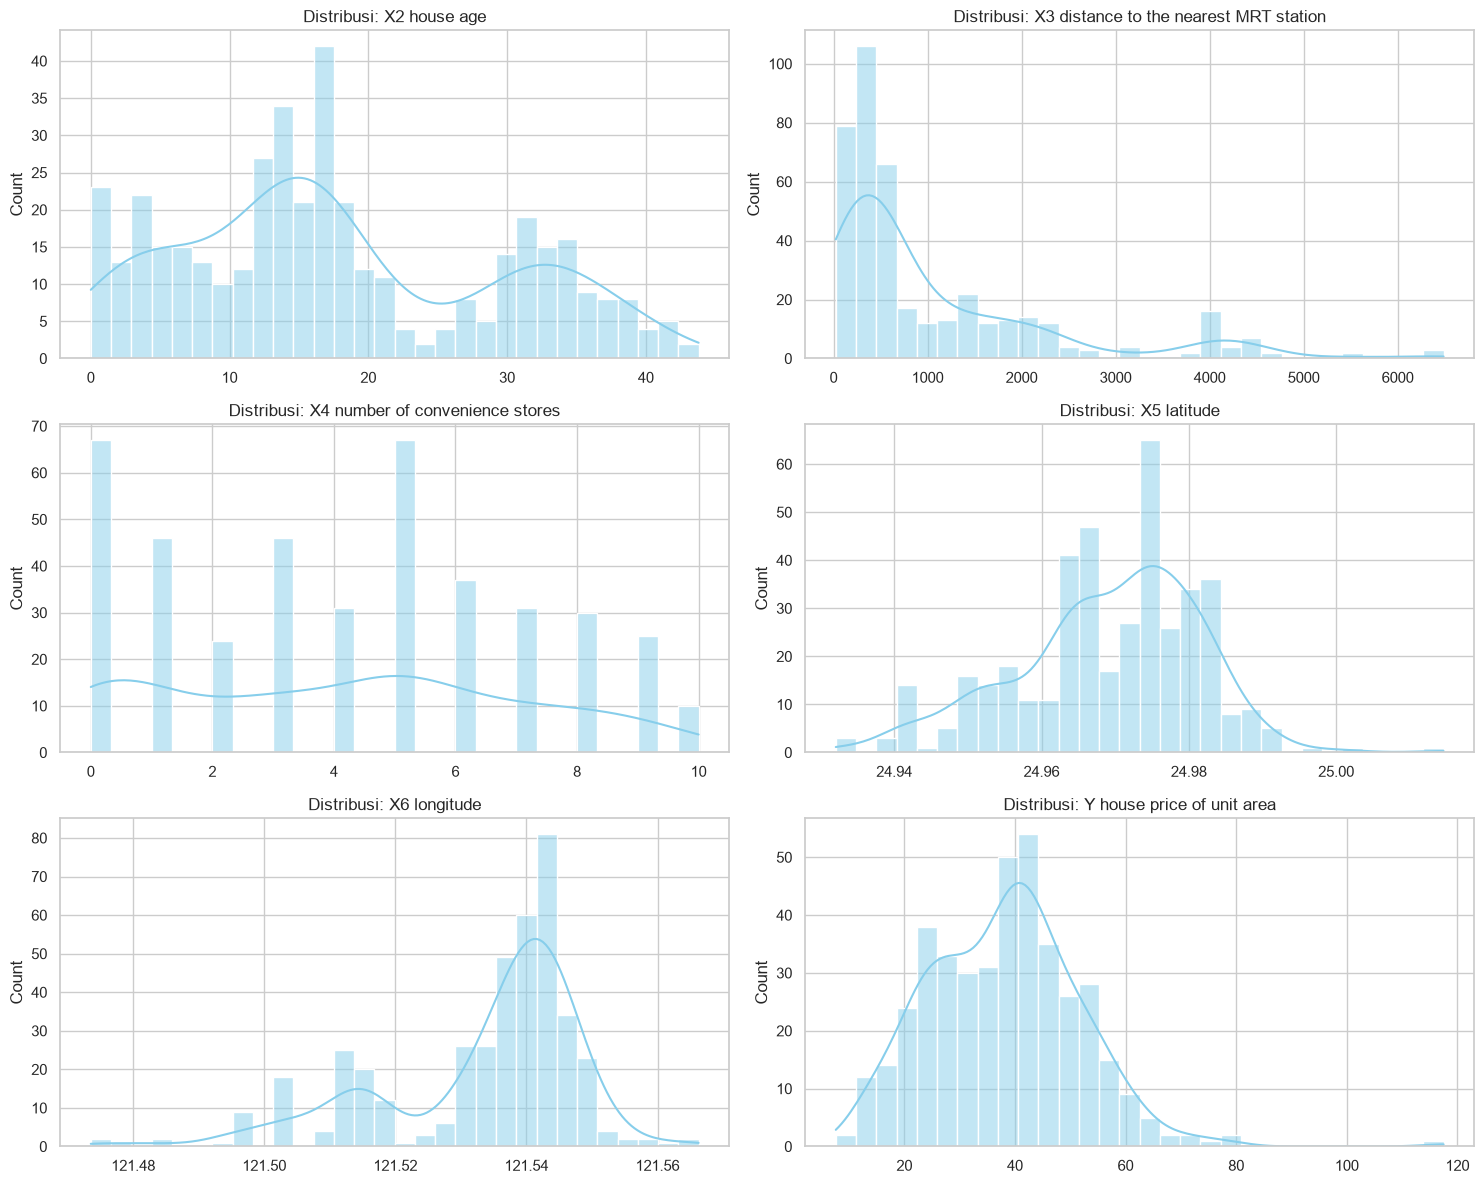

In [6]:
#Histogram 
sns.set(style="whitegrid")
plt.figure(figsize=(15, 12))
for i, col in enumerate(df.select_dtypes(include=[np.number]).columns, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], kde=True, color="skyblue", bins=30)
    plt.title(f'Distribusi: {col}')
    plt.xlabel('')
    plt.tight_layout()

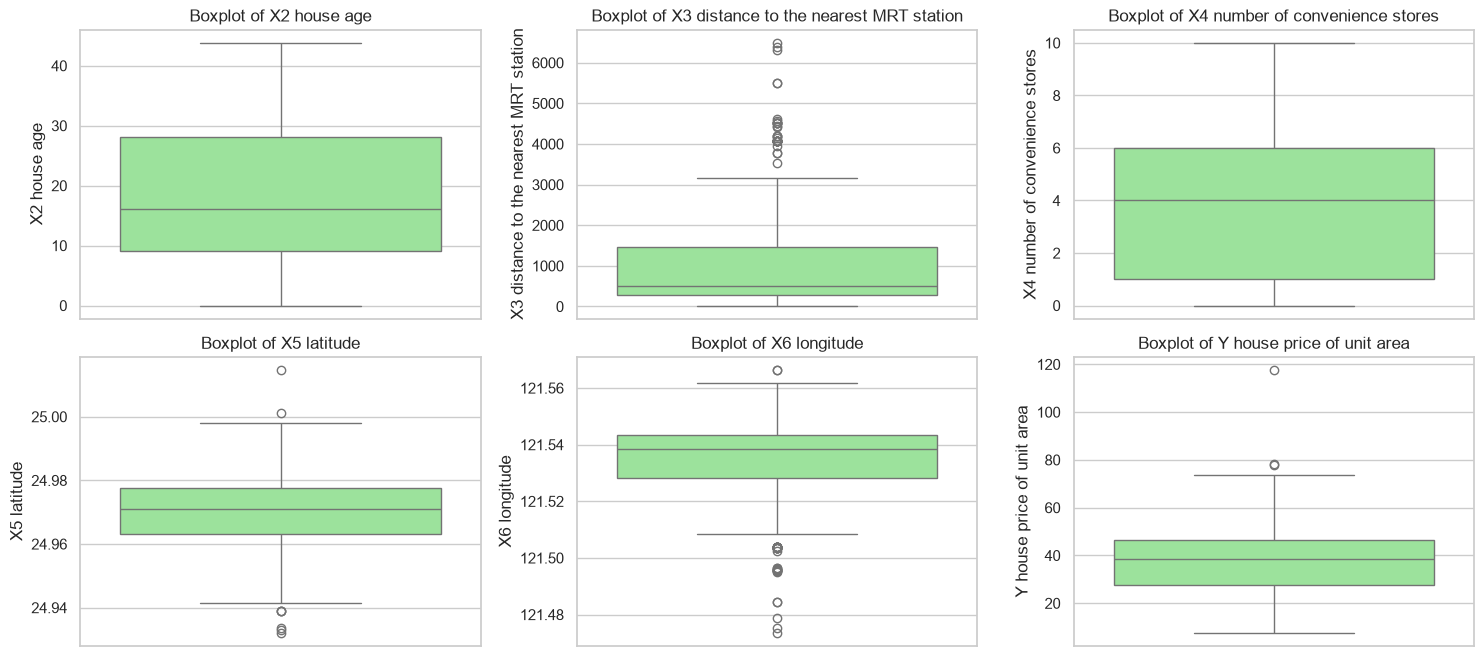

In [7]:
#Boxplot
plt.figure(figsize=(15, 10))
numerical_cols = df.select_dtypes(include=[np.number]).columns
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color="lightgreen")
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
plt.show()


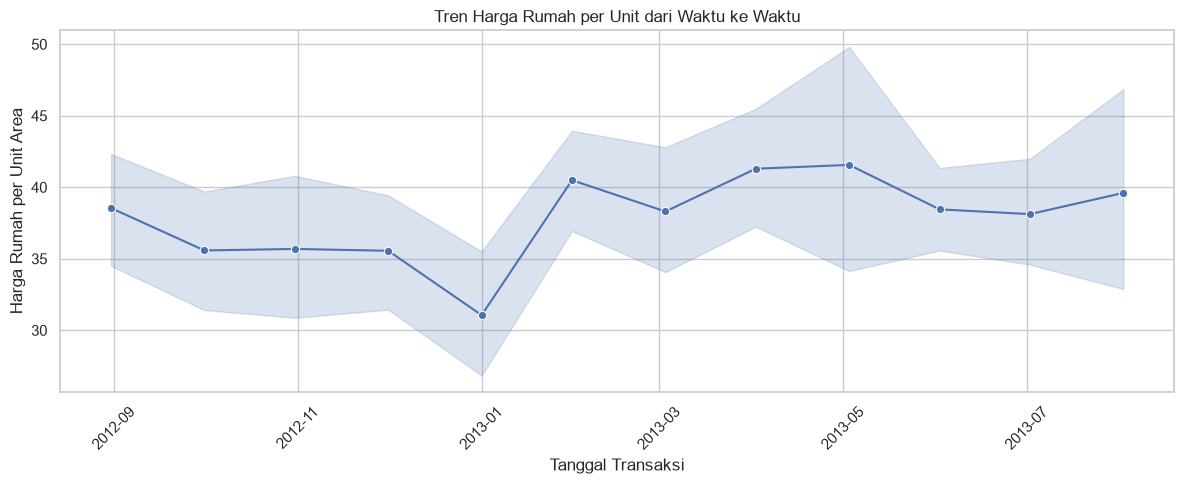

In [8]:
#Visualisasi harga rumah
plt.figure(figsize=(12, 5))
sns.lineplot(data=df.sort_values('X1 transaction date converted'), 
             x='X1 transaction date converted', 
             y='Y house price of unit area', 
             marker='o')
plt.title("Tren Harga Rumah per Unit dari Waktu ke Waktu")
plt.xlabel("Tanggal Transaksi")
plt.ylabel("Harga Rumah per Unit Area")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

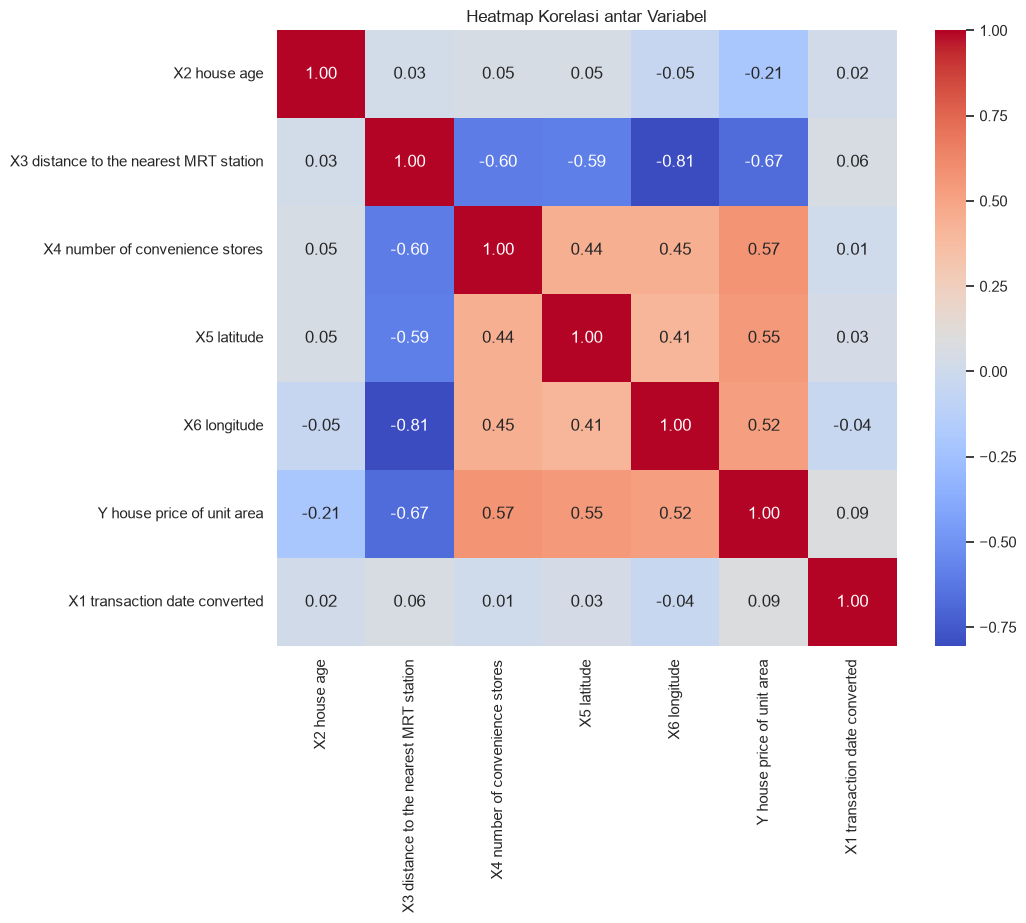

In [9]:
#Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi antar Variabel')
plt.show()

In [10]:
#SOAL 4-9
#Preprocessing
#Pembagian variabel
X = df.drop(columns=['Y house price of unit area', 'X1 transaction date converted'])
y = df['Y house price of unit area']
#Pembagian data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#Standarisasi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
#Dictionary menyimpan hasil
results = {}

In [12]:
#Grid search random forest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, cv=5, scoring='r2')
grid_rf.fit(X_train_scaled, y_train)
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
results['Random Forest'] = {
    'MSE': mean_squared_error(y_test, y_pred_rf),
    'R2': r2_score(y_test, y_pred_rf)
}

In [13]:
#Grid search SVR
param_grid_svr = {
    'C': [1, 10, 100],
    'gamma': ['scale', 0.1, 0.01],
    'kernel': ['rbf', 'linear']
}
grid_svr = GridSearchCV(SVR(), param_grid_svr, cv=5, scoring='r2')
grid_svr.fit(X_train_scaled, y_train)
best_svr = grid_svr.best_estimator_
y_pred_svr = best_svr.predict(X_test_scaled)
results['SVR'] = {
    'MSE': mean_squared_error(y_test, y_pred_svr),
    'R2': r2_score(y_test, y_pred_svr)
}

In [14]:
#Gradient Boosting Regressor
gbr = GradientBoostingRegressor(random_state=42, n_estimators=100, learning_rate=0.1, max_depth=3)
gbr.fit(X_train_scaled, y_train)
y_pred_gbr = gbr.predict(X_test_scaled)
results['Gradient Boosting'] = {
    'MSE': mean_squared_error(y_test, y_pred_gbr),
    'R2': r2_score(y_test, y_pred_gbr)
}

In [15]:
#LightGBM Regressor
lgbm = LGBMRegressor(random_state=42, n_estimators=100)
lgbm.fit(X_train_scaled, y_train)
y_pred_lgbm = lgbm.predict(X_test_scaled)
results['LightGBM'] = {
    'MSE': mean_squared_error(y_test, y_pred_lgbm),
    'R2': r2_score(y_test, y_pred_lgbm)
}

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000076 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 369
[LightGBM] [Info] Number of data points in the train set: 331, number of used features: 5
[LightGBM] [Info] Start training from score 38.391541
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

In [16]:
#Evaluasi model
results_df = pd.DataFrame(results).T
print(results_df)

                         MSE        R2
Random Forest      32.531193  0.806085
SVR                35.823068  0.786462
Gradient Boosting  31.689709  0.811101
LightGBM           34.700136  0.793156
